# IFT 6758 - Homework 2

In [ ]:
%load_ext autoreload
%autoreload 2

## Question 1

### a)
Begin by using the functions created in `q1.py` to make the data more informative and readable. Specifically, complete the following cells:

In [45]:
import pandas as pd
import numpy as np
import time
import matplotlib.pyplot as plt
import seaborn as sns
from q1 import count_labels, convert_id, convert_ids, contains_label, get_correlation
import json
sns.set(style="ticks")

In [ ]:
file = "data/audio_segments.csv"
df = pd.read_csv(file)

In [14]:
df.head(5)

,# YTID,start_seconds,end_seconds,positive_labels,label_count
0,--4gqARaEJE,0.0,10.0,"/m/068hy,/m/07q6cd_,/m/0bt9lr,/m/0jbk",4
1,--BfvyPmVMo,20.0,30.0,/m/03l9g,1
2,--U7joUcTCo,0.0,10.0,/m/01b_21,1
3,--i-y1v8Hy8,0.0,9.0,"/m/04rlf,/m/09x0r,/t/dd00004,/t/dd00005",4
4,-0BIyqJj9ZU,30.0,40.0,"/m/07rgt08,/m/07sq110,/t/dd00001",3


In [8]:
df.columns

Index(['# YTID', ' start_seconds', ' end_seconds', ' positive_labels'], dtype='object')

In [ ]:
str(df[" positive_labels"])

In [ ]:
df["label_count"] = df[" positive_labels"].apply(count_labels)

In [ ]:
# Add a new column called `label_names` with the processed human readable label names instead of label IDS

# Print the time taken for this operation (either using the time module or timeit). 
# Since we are only executing this code once it is relatively fine that it takes a couple of minutes. 
# However, for a larger dataset, it would be worth the time to speed it up 
# (for example by creating a ID -> name dictionary once and using that).

start = time.time()

df["label_names"]= df[" positive_labels"].apply(convert_ids)

end = time.time()

print("Time taken:", end - start, "seconds")

Time taken: 54.05726480484009 seconds


In [26]:
df

,# YTID,start_seconds,end_seconds,positive_labels,label_count,label_names
0,--4gqARaEJE,0.0,10.0,"/m/068hy,/m/07q6cd_,/m/0bt9lr,/m/0jbk",4,"Domestic animals, pets|Squeak|Dog|Animal"
1,--BfvyPmVMo,20.0,30.0,/m/03l9g,1,Hammer
2,--U7joUcTCo,0.0,10.0,/m/01b_21,1,Cough
3,--i-y1v8Hy8,0.0,9.0,"/m/04rlf,/m/09x0r,/t/dd00004,/t/dd00005",4,Music|Speech|Female singing|Child singing
4,-0BIyqJj9ZU,30.0,40.0,"/m/07rgt08,/m/07sq110,/t/dd00001",3,"Chuckle, chortle|Belly laugh|Baby laughter"
...,...,...,...,...,...,...
20366,zyF8TGSRvns,150.0,160.0,"/m/0dwsp,/m/0dwtp,/m/0f8s22,/m/0j45pbj",4,"Marimba, xylophone|Glockenspiel|Chime|Mallet p..."
20367,zz35Va7tYmA,30.0,40.0,"/m/012f08,/m/07q2z82,/m/07qmpdm,/m/0k4j",4,"Motor vehicle (road)|Accelerating, revving, vr..."
20368,zzD_oVgzKMc,30.0,40.0,/m/07pn_8q,1,Chopping (food)
20369,zzNdwF40ID8,70.0,80.0,"/m/04rlf,/m/0790c",2,Music|Sonar


In [27]:
# Display the DataFrame and save it to `audio_segments_clean.csv` (without index)
df.to_csv('audio_segments_clean.csv', index=False)

### b)

Next, using the clean DataFrame, complete the following cells to better understand the distribution of labels in the dataset. For each plot below, make sure to include appropriate **axis names** and a **title**.

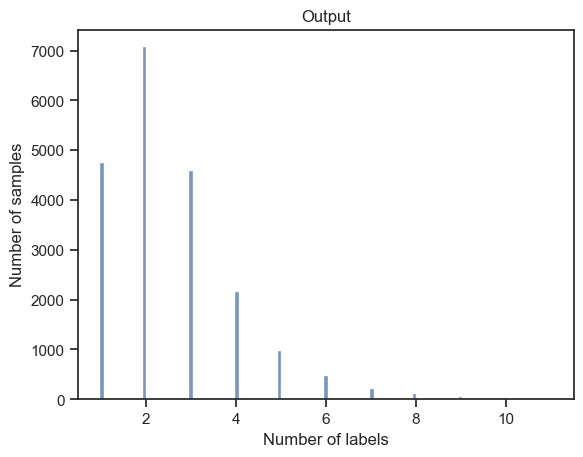

In [ ]:
# Using seaborn, create a histogram of the label count of the samples in the DataFrame

sns.histplot(df["label_count"])

plt.xlabel("Number of labels")
plt.ylabel("Number of samples")
plt.title("Output")
plt.show()

Follow the steps below to create a heatmap showing "correlation" between different labels. 
- Specifically, each cell of the heatmap should correspond to the probability that a sample with the corresponding row label also has the corresponding column label. 
- Just consider the labels ["Piano", "Classical music", "Speech", "Conversation", "Screaming"]. 

<Axes: >

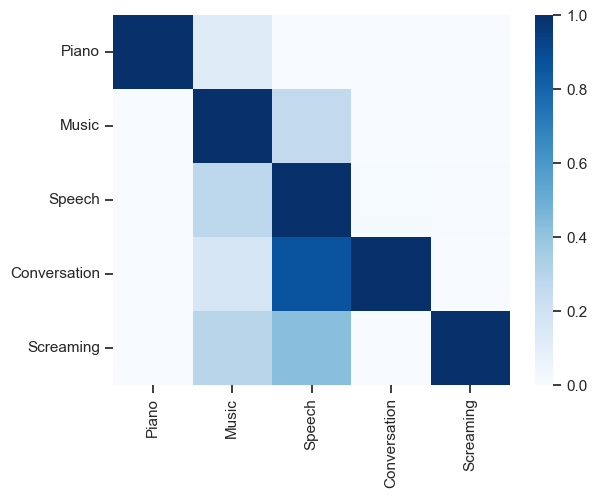

In [ ]:
labels = ["Piano", "Music", "Speech", "Conversation", "Screaming"]


grid= np.zeros((len(labels), len(labels)))

for i in range(len(labels)):
    for j in range(len(labels)):
        if i == j:
            grid[i, j] = 1.0
        else:
            grid[i, j] = get_correlation(df["label_names"], labels[i], labels[j])

# There are a couple ways to approach this, the way we recommend here is to first build a 2D grid where each
# value is the correlation value between the corresponding row/column using the functions created in q1.py.


# Then using sns.heatmap, create the heatmap, taking advantage of xticklabels and yticklabels to set the label names
# as tick values

sns.heatmap(grid, cmap="Blues", xticklabels=labels, yticklabels=labels)


## Question 2
Question 2 has no notebook component, just fill out the `q2.py` file.

## Question 3

Download the audio for the following labels using the function created in `q3.py`

In [51]:
from q3 import data_pipeline, rename_files, filter_df
from q2 import cut_audio

In [2]:
# Download "Cough"
label="Cough"
path="audio_segments_clean.csv"
print(filter_df(path,label))
print(len(filter_df(path,label)))
data_pipeline(path,label)
rename_files(f"{label}_cut", path)

            # YTID   start_seconds   end_seconds  \
2      --U7joUcTCo             0.0          10.0   
691    0iiwZ2_9Vi8            90.0         100.0   
716    0mZQ6Q-viPw            10.0          20.0   
819    130v5XJl8G0            70.0          80.0   
1015   1Xmw9VUzvLY           150.0         160.0   
1605   39IZIbmQPzA            40.0          50.0   
1667   3Liy9uBgsQM            60.0          70.0   
1781   3id3zRRZBVM            50.0          60.0   
1896   40fIOkLK3j4            60.0          70.0   
2543   5wbc84KnDS0            60.0          70.0   
3138   7lO9BbTaezE             0.0          10.0   
3753   9h3a7fN0f-c           240.0         250.0   
4018   AIVt3e5EVtc            70.0          80.0   
4224   AlPu_yxLT2g           230.0         240.0   
4561   BZU01hhyVKs           480.0         490.0   
5420   DYTLct-5tVs             0.0          10.0   
6676   HJg4jZNv1pc           150.0         160.0   
6696   HMnF8n9c5-Y            30.0          40.0   
7101   IYllz

Cough:   0%|          | 0/60 [00:00<?, ?it/s]

[youtube] Extracting URL: https://www.youtube.com/watch?v=--U7joUcTCo
[youtube] --U7joUcTCo: Downloading webpage
[youtube] --U7joUcTCo: Downloading tv simply player API JSON
[youtube] --U7joUcTCo: Downloading tv client config
[youtube] --U7joUcTCo: Downloading tv player API JSON
[info] --U7joUcTCo: Downloading 1 format(s): 251
[download] Sleeping 5.00 seconds as required by the site...
[download] Destination: Cough_raw/--U7joUcTCo
[download] 100% of  120.01KiB in 00:00:00 at 341.56KiB/s 
[ExtractAudio] Destination: Cough_raw/--U7joUcTCo.mp3
Deleting original file Cough_raw/--U7joUcTCo (pass -k to keep)


ffmpeg version 8.0 Copyright (c) 2000-2025 the FFmpeg developers
  built with Apple clang version 17.0.0 (clang-1700.0.13.3)
  configuration: --prefix=/opt/homebrew/Cellar/ffmpeg/8.0_1 --enable-shared --enable-pthreads --enable-version3 --cc=clang --host-cflags= --host-ldflags='-Wl,-ld_classic' --enable-ffplay --enable-gnutls --enable-gpl --enable-libaom --enable-libaribb24 --enable-libbluray --enable-libdav1d --enable-libharfbuzz --enable-libjxl --enable-libmp3lame --enable-libopus --enable-librav1e --enable-librist --enable-librubberband --enable-libsnappy --enable-libsrt --enable-libssh --enable-libsvtav1 --enable-libtesseract --enable-libtheora --enable-libvidstab --enable-libvmaf --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx264 --enable-libx265 --enable-libxml2 --enable-libxvid --enable-lzma --enable-libfontconfig --enable-libfreetype --enable-frei0r --enable-libass --enable-libopencore-amrnb --enable-libopencore-amrwb --enable-libopenjpeg --enable-libspeex --e

Cut successful: Cough_cut/--U7joUcTCo.mp3
[youtube] Extracting URL: https://www.youtube.com/watch?v=0iiwZ2_9Vi8
[youtube] 0iiwZ2_9Vi8: Downloading webpage
[youtube] 0iiwZ2_9Vi8: Downloading tv simply player API JSON
[youtube] 0iiwZ2_9Vi8: Downloading tv client config
[youtube] 0iiwZ2_9Vi8: Downloading tv player API JSON
[info] 0iiwZ2_9Vi8: Downloading 1 format(s): 251
[download] Sleeping 5.00 seconds as required by the site...


...

[WARN] wU1xLUAWAyA: ffmpeg error (see stderr output for detail)
[youtube] Extracting URL: https://www.youtube.com/watch?v=wuvn-vp5InE
[youtube] wuvn-vp5InE: Downloading webpage
[youtube] wuvn-vp5InE: Downloading tv simply player API JSON
[youtube] wuvn-vp5InE: Downloading tv client config
[youtube] wuvn-vp5InE: Downloading tv player API JSON
[info] wuvn-vp5InE: Downloading 1 format(s): 251
[download] Sleeping 5.00 seconds as required by the site...
[download] Destination: Cough_raw/wuvn-vp5InE
[download] 100% of  121.52KiB in 00:00:00 at 820.39KiB/s 
[ExtractAudio] Destination: Cough_raw/wuvn-vp5InE.mp3
Deleting original file Cough_raw/wuvn-vp5InE (pass -k to keep)


ffmpeg version 8.0 Copyright (c) 2000-2025 the FFmpeg developers
  built with Apple clang version 17.0.0 (clang-1700.0.13.3)
  configuration: --prefix=/opt/homebrew/Cellar/ffmpeg/8.0_1 --enable-shared --enable-pthreads --enable-version3 --cc=clang --host-cflags= --host-ldflags='-Wl,-ld_classic' --enable-ffplay --enable-gnutls --enable-gpl --enable-libaom --enable-libaribb24 --enable-libbluray --enable-libdav1d --enable-libharfbuzz --enable-libjxl --enable-libmp3lame --enable-libopus --enable-librav1e --enable-librist --enable-librubberband --enable-libsnappy --enable-libsrt --enable-libssh --enable-libsvtav1 --enable-libtesseract --enable-libtheora --enable-libvidstab --enable-libvmaf --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx264 --enable-libx265 --enable-libxml2 --enable-libxvid --enable-lzma --enable-libfontconfig --enable-libfreetype --enable-frei0r --enable-libass --enable-libopencore-amrnb --enable-libopencore-amrwb --enable-libopenjpeg --enable-libspeex --e

Cut successful: Cough_cut/wuvn-vp5InE.mp3
[youtube] Extracting URL: https://www.youtube.com/watch?v=yMNs4gCJn1c
[youtube] yMNs4gCJn1c: Downloading webpage
[youtube] yMNs4gCJn1c: Downloading tv simply player API JSON
[youtube] yMNs4gCJn1c: Downloading tv client config
[youtube] yMNs4gCJn1c: Downloading tv player API JSON
[info] yMNs4gCJn1c: Downloading 1 format(s): 251
[download] Sleeping 5.00 seconds as required by the site...
[download] Destination: Cough_raw/yMNs4gCJn1c
[download] 100% of  529.94KiB in 00:00:01 at 385.67KiB/s 
[ExtractAudio] Destination: Cough_raw/yMNs4gCJn1c.mp3
Deleting original file Cough_raw/yMNs4gCJn1c (pass -k to keep)


ffmpeg version 8.0 Copyright (c) 2000-2025 the FFmpeg developers
  built with Apple clang version 17.0.0 (clang-1700.0.13.3)
  configuration: --prefix=/opt/homebrew/Cellar/ffmpeg/8.0_1 --enable-shared --enable-pthreads --enable-version3 --cc=clang --host-cflags= --host-ldflags='-Wl,-ld_classic' --enable-ffplay --enable-gnutls --enable-gpl --enable-libaom --enable-libaribb24 --enable-libbluray --enable-libdav1d --enable-libharfbuzz --enable-libjxl --enable-libmp3lame --enable-libopus --enable-librav1e --enable-librist --enable-librubberband --enable-libsnappy --enable-libsrt --enable-libssh --enable-libsvtav1 --enable-libtesseract --enable-libtheora --enable-libvidstab --enable-libvmaf --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx264 --enable-libx265 --enable-libxml2 --enable-libxvid --enable-lzma --enable-libfontconfig --enable-libfreetype --enable-frei0r --enable-libass --enable-libopencore-amrnb --enable-libopencore-amrwb --enable-libopenjpeg --enable-libspeex --e

Cut successful: Cough_cut/yMNs4gCJn1c.mp3


In [47]:
# Download "Hammer"

label="Hammer"
path="audio_segments_clean.csv"
print(filter_df(path,label))
print(len(filter_df(path,label)))
data_pipeline(path,label)
rename_files(f"{label}_cut", path)

            # YTID   start_seconds   end_seconds  \
1      --BfvyPmVMo            20.0          30.0   
427    03aJ_RcnBko           550.0         560.0   
450    07AQUF6A_mg           290.0         300.0   
510    0GNNFBrRz1E            40.0          50.0   
677    0fsntL6RKww            30.0          40.0   
858    19knOj43yZE           330.0         340.0   
1163   1wdCX1HmRyk           140.0         150.0   
1483   2pYtX-Stpys            30.0          40.0   
1622   3CnwUQZ6q78           130.0         140.0   
1893   402OOck5CAk            30.0          40.0   
2174   4mHLCOzd2No            20.0          30.0   
2437   5etqUVLDcE4           140.0         150.0   
2534   5tyZiD0-8z4           320.0         330.0   
2602   660s2w9DSgc           200.0         210.0   
2658   6GLRCkbptwQ            40.0          50.0   
2795   6gchJ1prCFM             0.0          10.0   
3946   AAySJVt6bys            30.0          40.0   
4428   BDznJMSoAoQ            30.0          40.0   
4506   BPeLf

Hammer:   0%|                                            | 0/60 [00:00<?, ?it/s]

[youtube] Extracting URL: https://www.youtube.com/watch?v=--BfvyPmVMo
[youtube] --BfvyPmVMo: Downloading webpage
[youtube] --BfvyPmVMo: Downloading tv simply player API JSON
[youtube] --BfvyPmVMo: Downloading tv client config
[youtube] --BfvyPmVMo: Downloading tv player API JSON
[info] --BfvyPmVMo: Downloading 1 format(s): 251
[download] Sleeping 5.00 seconds as required by the site...


ERROR: unable to download video data: HTTP Error 403: Forbidden
ffmpeg version 8.0 Copyright (c) 2000-2025 the FFmpeg developers
  built with Apple clang version 17.0.0 (clang-1700.0.13.3)
  configuration: --prefix=/opt/homebrew/Cellar/ffmpeg/8.0_1 --enable-shared --enable-pthreads --enable-version3 --cc=clang --host-cflags= --host-ldflags='-Wl,-ld_classic' --enable-ffplay --enable-gnutls --enable-gpl --enable-libaom --enable-libaribb24 --enable-libbluray --enable-libdav1d --enable-libharfbuzz --enable-libjxl --enable-libmp3lame --enable-libopus --enable-librav1e --enable-librist --enable-librubberband --enable-libsnappy --enable-libsrt --enable-libssh --enable-libsvtav1 --enable-libtesseract --enable-libtheora --enable-libvidstab --enable-libvmaf --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx264 --enable-libx265 --enable-libxml2 --enable-libxvid --enable-lzma --enable-libfontconfig --enable-libfreetype --enable-frei0r --enable-libass --enable-libopencore-amrnb --ena

[WARN] https://www.youtube.com/watch?v=--BfvyPmVMo: ERROR: unable to download video data: HTTP Error 403: Forbidden
[WARN] --BfvyPmVMo: ffmpeg error (see stderr output for detail)
[youtube] Extracting URL: https://www.youtube.com/watch?v=03aJ_RcnBko
[youtube] 03aJ_RcnBko: Downloading webpage
[youtube] 03aJ_RcnBko: Downloading tv simply player API JSON
[youtube] 03aJ_RcnBko: Downloading tv client config
[youtube] 03aJ_RcnBko: Downloading tv player API JSON
[info] 03aJ_RcnBko: Downloading 1 format(s): 251
[download] Sleeping 5.00 seconds as required by the site...


...

[WARN] https://www.youtube.com/watch?v=uYipfjHCJm8: ERROR: unable to download video data: HTTP Error 403: Forbidden
[WARN] uYipfjHCJm8: ffmpeg error (see stderr output for detail)
[youtube] Extracting URL: https://www.youtube.com/watch?v=vYTbV-TAxU8
[youtube] vYTbV-TAxU8: Downloading webpage
[youtube] vYTbV-TAxU8: Downloading tv simply player API JSON
[youtube] vYTbV-TAxU8: Downloading tv client config
[youtube] vYTbV-TAxU8: Downloading tv player API JSON
[info] vYTbV-TAxU8: Downloading 1 format(s): 251
[download] Sleeping 4.00 seconds as required by the site...


ERROR: unable to download video data: HTTP Error 403: Forbidden
ffmpeg version 8.0 Copyright (c) 2000-2025 the FFmpeg developers
  built with Apple clang version 17.0.0 (clang-1700.0.13.3)
  configuration: --prefix=/opt/homebrew/Cellar/ffmpeg/8.0_1 --enable-shared --enable-pthreads --enable-version3 --cc=clang --host-cflags= --host-ldflags='-Wl,-ld_classic' --enable-ffplay --enable-gnutls --enable-gpl --enable-libaom --enable-libaribb24 --enable-libbluray --enable-libdav1d --enable-libharfbuzz --enable-libjxl --enable-libmp3lame --enable-libopus --enable-librav1e --enable-librist --enable-librubberband --enable-libsnappy --enable-libsrt --enable-libssh --enable-libsvtav1 --enable-libtesseract --enable-libtheora --enable-libvidstab --enable-libvmaf --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx264 --enable-libx265 --enable-libxml2 --enable-libxvid --enable-lzma --enable-libfontconfig --enable-libfreetype --enable-frei0r --enable-libass --enable-libopencore-amrnb --ena

[WARN] https://www.youtube.com/watch?v=vYTbV-TAxU8: ERROR: unable to download video data: HTTP Error 403: Forbidden
[WARN] vYTbV-TAxU8: ffmpeg error (see stderr output for detail)
[youtube] Extracting URL: https://www.youtube.com/watch?v=wG59D9drJGY
[youtube] wG59D9drJGY: Downloading webpage
[youtube] wG59D9drJGY: Downloading tv simply player API JSON
[youtube] wG59D9drJGY: Downloading tv client config
[youtube] wG59D9drJGY: Downloading tv player API JSON
[info] wG59D9drJGY: Downloading 1 format(s): 251
[download] Sleeping 5.00 seconds as required by the site...


ERROR: unable to download video data: HTTP Error 403: Forbidden
ffmpeg version 8.0 Copyright (c) 2000-2025 the FFmpeg developers
  built with Apple clang version 17.0.0 (clang-1700.0.13.3)
  configuration: --prefix=/opt/homebrew/Cellar/ffmpeg/8.0_1 --enable-shared --enable-pthreads --enable-version3 --cc=clang --host-cflags= --host-ldflags='-Wl,-ld_classic' --enable-ffplay --enable-gnutls --enable-gpl --enable-libaom --enable-libaribb24 --enable-libbluray --enable-libdav1d --enable-libharfbuzz --enable-libjxl --enable-libmp3lame --enable-libopus --enable-librav1e --enable-librist --enable-librubberband --enable-libsnappy --enable-libsrt --enable-libssh --enable-libsvtav1 --enable-libtesseract --enable-libtheora --enable-libvidstab --enable-libvmaf --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx264 --enable-libx265 --enable-libxml2 --enable-libxvid --enable-lzma --enable-libfontconfig --enable-libfreetype --enable-frei0r --enable-libass --enable-libopencore-amrnb --ena

[WARN] https://www.youtube.com/watch?v=wG59D9drJGY: ERROR: unable to download video data: HTTP Error 403: Forbidden
[WARN] wG59D9drJGY: ffmpeg error (see stderr output for detail)


As you've probably noticed, downloading all this audio data is slow (and as such we only required you to download 2 of the labels). In many cases, it is possible to get significant performance increases by using either multiprocessing (https://docs.python.org/3/library/multiprocessing.html) or multithreading (https://docs.python.org/3/library/threading.html) which could for example allow you to download multiple audio files in parallel. 

As a good rule of thumb, use multithreading when your programs is IO-bound (for example here) and multiprocessing when it is CPU-bound (and thus make use of all the cores of your CPU)

## Question 4
For the following cells, use the ID "0GNNFBrRz1E". Complete the functions and run the cells provided below.

In [66]:
import librosa

In [62]:
from IPython.display import Audio

path = "Hammer_cut/0GNNFBrRz1E_40_50_10.mp3"

Audio(path)

One way to visualize audio is through the use of mel-spectrograms. At a very high level, Mel-spectrograms convert audio to a 2D image through the use of the Fourier transform (more details can be found here: https://medium.com/analytics-vidhya/understanding-the-mel-spectrogram-fca2afa2ce53)

In [67]:
stft_hopsize = 128
n_fft = 512
sample_rate = 16000

def to_log_scale(mel: np.ndarray) -> np.ndarray:
    mel = np.log(mel + 1e-6)/2.0
    return mel

def create_mel_spectrogram(mp3_path: str) -> np.ndarray:
    """ 
    Using librosa (https://librosa.org/doc/main/generated/librosa.feature.melspectrogram.html) write a function
    that:
    1. Loads in audio from a mp3_path (using librosa)
    2. Converts it to a mel-spectrogram (using the parameters provided above)
    3. Applies the logscale transformation to the mel-spectrogram (provided above once again)
    4. Returns the transformed mel-spectrogram
    
    Make sure to pass the correct sample rate
    """
    y, sr = librosa.load(mp3_path, sr=sample_rate)
    
    mel = librosa.feature.melspectrogram(y=y, sr=sr, n_fft=n_fft, hop_length=stft_hopsize, fmax=sr // 2)
    mel_log=to_log_scale(mel)
    return mel_log
    # TODO  

create_mel_spectrogram("Hammer_cut/0GNNFBrRz1E_40_50_10.mp3")

array([[-1.8937742, -1.5488122, -1.4473828, ..., -2.892937 , -2.2050893,
        -2.5334241],
       [-2.0273387, -1.7301224, -1.6916125, ..., -2.8176634, -2.1396763,
        -2.4985297],
       [-2.2094831, -2.0216744, -2.206432 , ..., -2.7434962, -2.073272 ,
        -2.4580033],
       ...,
       [-6.378085 , -6.569799 , -6.61537  , ..., -6.668133 , -6.6196375,
        -6.77567  ],
       [-6.590423 , -6.640099 , -6.6946783, ..., -6.8196526, -6.79205  ,
        -6.848466 ],
       [-6.8254204, -6.871716 , -6.901831 , ..., -6.901888 , -6.9048038,
        -6.9070253]], shape=(128, 1251), dtype=float32)

Audio data can also be visualized by looking at the waveform (i.e. as a line plot of the amplitude values). We will combine both visualizations methods below. The resulting plot should look something like:
![alt text](images/combined_plot.png "Combined Plot")

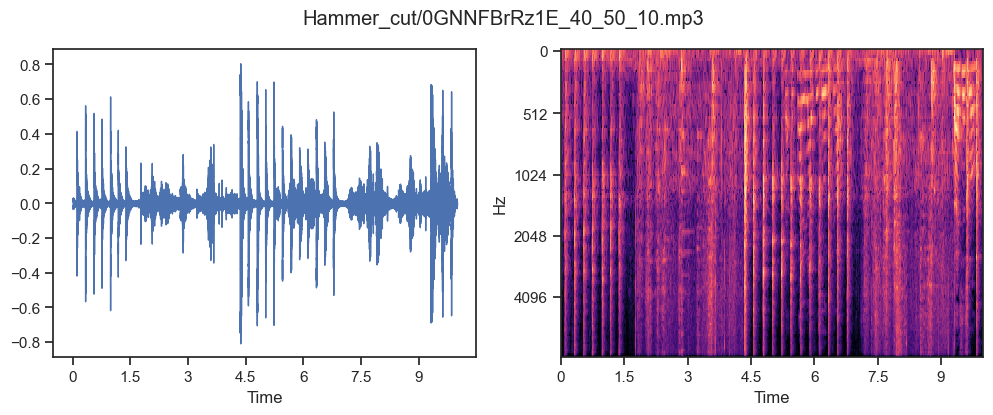

In [78]:
def plot_audio(mp3_path: str) -> None:
    """ 
    Using matplotlib and create_mel_spectrogram() write a function that takes a mp3_path and plots
    both the waveform (line plot of amplitudes) and the mel-spectrogram side-by-side as subplots.
    
    Use the path as a single main title for both subplots
    """
    

    # TODO

    #t = np.arange(len(y)) / sr

    # 2) Compute (log) mel-spectrogram using your helper
    y, sr = librosa.load(mp3_path, sr=sample_rate)

    mel_log = create_mel_spectrogram(mp3_path)

    # 3) Make side-by-side subplots
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    # waveform
    plt.subplot(1, 2, 1)
    librosa.display.waveshow(y, sr=sr)

    # mel spectrogram
    plt.subplot(1, 2, 2)
    librosa.display.specshow(mel_log, sr=sr, hop_length=stft_hopsize,
                             x_axis="time", y_axis="mel", fmax=sr//2)

    plt.gca().invert_yaxis()
    plt.suptitle(mp3_path)
    plt.show()

plot_audio("Hammer_cut/0GNNFBrRz1E_40_50_10.mp3")